# Análise de regressão linear simples

**Enrico Manzolli Bertoni - RA: 176259**

**Felipe Scarpin Mesquita - RA: 187399**

**Tema:** salários e outras remunerações, emprego e porte dos municípios brasileiros em 2021.

## Introdução: motivação, variáveis e objetivos

Escolhemos estudar a relação entre emprego, porte municipal e remunerações formais para compreender como a atividade econômica se distribui entre cidades brasileiras. O tema permite investigar se municípios com mais trabalhadores, estabelecimentos e habitantes também concentram maior massa de remunerações. Essa comparação ajuda a descrever diferenças econômicas municipais, sem confundir remuneração total com salário individual.

Analisamos **5.570 municípios brasileiros em 2021**, com uma observação por município. A base reúne os quatro indicadores positivos e não exclui cidades por influência ou para melhorar o ajuste. Trata-se de um **corte transversal**, sem sequência temporal.

| Variável | Definição | Unidade na análise |
|---|---|---|
| Y | Total anual de salários e outras remunerações | Milhões de reais nominais de 2021 |
| x1 | Número de unidades locais (estabelecimentos) | Milhares de unidades |
| x2 | Pessoal ocupado assalariado | Milhares de pessoas |
| x3 | População residente estimada | Milhares de pessoas |

**Perguntas e objetivos:**

1. Como emprego assalariado, unidades locais e população se relacionam com a remuneração total municipal?
2. As transformações das explicativas tornam essas relações mais próximas de retas? Qual explicativa escolher para a regressão simples?
3. Qual é a reta ajustada e como interpretar seus intervalos de confiança e predição?
4. Os gráficos dos resíduos sustentam as suposições do modelo e seu uso para previsão?

**Fontes:** IBGE, [CEMPRE — tabela 1685](https://sidra.ibge.gov.br/tabela/1685), variáveis 662, 706 e 708, e [População estimada — tabela 6579](https://sidra.ibge.gov.br/tabela/6579), variável 9324; ano 2021 em ambas. A base preparada é lida automaticamente do CSV público no GitHub pela célula de entrada dos dados.

**Planilhas:** [variáveis antes das transformações](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/originais/base_original.csv) e [variáveis antes e após as transformações](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/transformados/base_com_transformacoes.csv). Os links abrem os arquivos no repositório público do GitHub, onde podem ser consultados e baixados. Os CSVs usam ponto e vírgula como separador e vírgula decimal.

As remunerações abrangem as organizações formais do CEMPRE, e não todos os rendimentos dos moradores. Emprego, estabelecimentos e população medem porte municipal; uma associação forte entre seus totais não demonstra causalidade. Local de trabalho e de residência podem diferir, e a independência espacial entre municípios não foi demonstrada.

## Preparação do ambiente

No Colab, carregue este notebook, confirme que a sessão executa **R** e execute as células em ordem antes da apresentação. A sessão precisa conter apenas este notebook e ter acesso à internet: a base é lida automaticamente do GitHub, e as pastas e os CSVs de saída são criados durante a execução. Os links das planilhas apontam para o GitHub, sem depender dos arquivos da sessão. A instalação de pacotes ausentes requer internet; confira também as permissões do notebook compartilhado.

Localmente, use Jupyter ou VS Code com o kernel R (IRkernel). Ambiente validado: R 4.6.2. Se necessário, instale e registre o kernel em uma sessão R com `install.packages("IRkernel")` e `IRkernel::installspec()`.

Os CSVs são gravados nas subpastas de `dados/`, e os gráficos aparecem nas saídas das células. No GitHub também estão disponíveis os gráficos exportados e o relatório de validação local na pasta `resultados/`.

In [1]:
# Pacotes necessários
pacotes <- c("car", "MASS", "nortest", "lmtest")

# Verificar, instalar e carregar os pacotes
for (pacote in pacotes) {
  if (!requireNamespace(pacote, quietly = TRUE)) {
    install.packages(pacote, repos = "https://cloud.r-project.org")
  }
  carregou <- suppressPackageStartupMessages(
    require(pacote, character.only = TRUE)
  )
  if (carregou) {
    cat(pacote, ": carregado com sucesso\n")
  } else {
    stop(paste("Erro ao carregar", pacote))
  }
}
options(repr.plot.width = 12, repr.plot.height = 9, digits = 6)
set.seed(1711)
for (pasta in c("dados/originais", "dados/transformados", "dados/diagnosticos", "resultados")) {
  dir.create(pasta, recursive = TRUE, showWarnings = FALSE)
}

car : carregado com sucesso
MASS : carregado com sucesso
nortest : carregado com sucesso
lmtest : carregado com sucesso


In [ ]:
# Entrada dos dados: leitura automática do CSV público no GitHub
url_dados <- paste0(
  "https://raw.githubusercontent.com/embertoni/TrabalhoFinal-IAR/",
  "main/parte1/dados/originais/base_original.csv"
)

dados <- read.csv2(url_dados, fileEncoding = "UTF-8", colClasses = c(codigo = "character"))

y <- dados$salarios_mil_reais / 1000  # remunerações em milhões de reais
x1 <- dados$unidades / 1000           # unidades locais em milhares
x2 <- dados$assalariados / 1000       # assalariados em milhares
x3 <- dados$populacao / 1000          # população em milhares

dados$y <- y
dados$x1 <- x1
dados$x2 <- x2
dados$x3 <- x3

nrow(dados)
head(dados)
stopifnot(nrow(dados) == 5570, !anyDuplicated(dados$codigo), all(dados$ano == 2021), all(is.finite(y)), all(x1 > 0), all(x2 > 0), all(x3 > 0))
write.csv2(dados, "dados/originais/base_original.csv", row.names = FALSE, fileEncoding = "UTF-8")

[1] 5570

,codigo,municipio,unidades,assalariados,salarios_mil_reais,populacao,ano,y,x1,x2,x3
,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,1100015,Alta Floresta D'Oeste - RO,521,2356,68629,22516,2021,68.629,0.521,2.356,22.516
2,1100023,Ariquemes - RO,2879,17176,488764,111148,2021,488.764,2.879,17.176,111.148
3,1100031,Cabixi - RO,57,492,14172,5067,2021,14.172,0.057,0.492,5.067
4,1100049,Cacoal - RO,2817,17117,473251,86416,2021,473.251,2.817,17.117,86.416
5,1100056,Cerejeiras - RO,513,2248,65510,16088,2021,65.510,0.513,2.248,16.088
6,1100064,Colorado do Oeste - RO,352,2223,56121,15213,2021,56.121,0.352,2.223,15.213


## Parte 1 — diagramas de dispersão

### Variáveis originais

Examinamos Y e as três candidatas antes de escolher uma explicativa. As escalas em milhares mudam a unidade de X, sem alterar sua correlação com Y.

### Leitura dos gráficos

Os diagramas mostram o conjunto completo e uma janela até o percentil 99 de X e Y. O título informa quantos pontos estão fora da janela; o total pode exceder 1%, porque o limite é aplicado aos dois eixos. É **apenas zoom**: todos os 5.570 municípios permanecem na análise. As três cidades com maior remuneração são identificadas no gráfico completo; pontos menores e transparentes reduzem a sobreposição.

In [3]:
# Mesmos dados em duas janelas: todos os municípios e detalhe até P99.
# Os limites só afetam o desenho; nenhuma observação sai da regressão.
grafico_visual <- function(a, b, nome_x, zoom=FALSE, ajuste=NULL) {
  limite_x <- if (zoom) quantile(a,0.99) else max(a)
  limite_y <- if (zoom) quantile(b,0.99) else max(b)*1.08
  fora <- sum(a > limite_x | b > limite_y)
  titulo <- if (zoom) paste("Zoom P99 -",fora,"pontos fora da janela") else "Todos os municípios"
  plot(a,b,xlim=c(min(a),limite_x),ylim=c(min(b),limite_y),
       xlab=nome_x,ylab="Remunerações (milhões R$)",main=titulo,
       pch=19,cex=0.45,col=adjustcolor("steelblue",alpha.f=0.4),cex.main=0.85)
  if (!is.null(ajuste)) abline(ajuste,col="red")
  if (!zoom) {
    cidades <- order(b,decreasing=TRUE)[1:3]
    points(a[cidades],b[cidades],pch=19,cex=0.7,col="firebrick")
    text(a[cidades],b[cidades],labels=dados$municipio[cidades],pos=2,cex=0.6,col="firebrick")
  }
}

       y                  x1                x2                 x3          
 Min.   :8.80e-01   Min.   :  0.006   Min.   :   0.057   Min.   :7.71e-01  
 1st Qu.:1.37e+01   1st Qu.:  0.081   1st Qu.:   0.526   1st Qu.:5.45e+00  
 Median :3.11e+01   Median :  0.185   Median :   1.148   Median :1.17e+01  
 Mean   :3.58e+02   Mean   :  1.135   Mean   :   8.549   Mean   :3.83e+01  
 3rd Qu.:9.24e+01   3rd Qu.:  0.520   3rd Qu.:   3.208   3rd Qu.:2.58e+01  
 Max.   :3.06e+05   Max.   :681.246   Max.   :5013.099   Max.   :1.24e+04  

,y,x1,x2,x3
y,1.000000,0.984671,0.992291,0.957654
x1,0.984671,1.000000,0.988425,0.957632
x2,0.992291,0.988425,1.000000,0.977920
x3,0.957654,0.957632,0.977920,1.000000


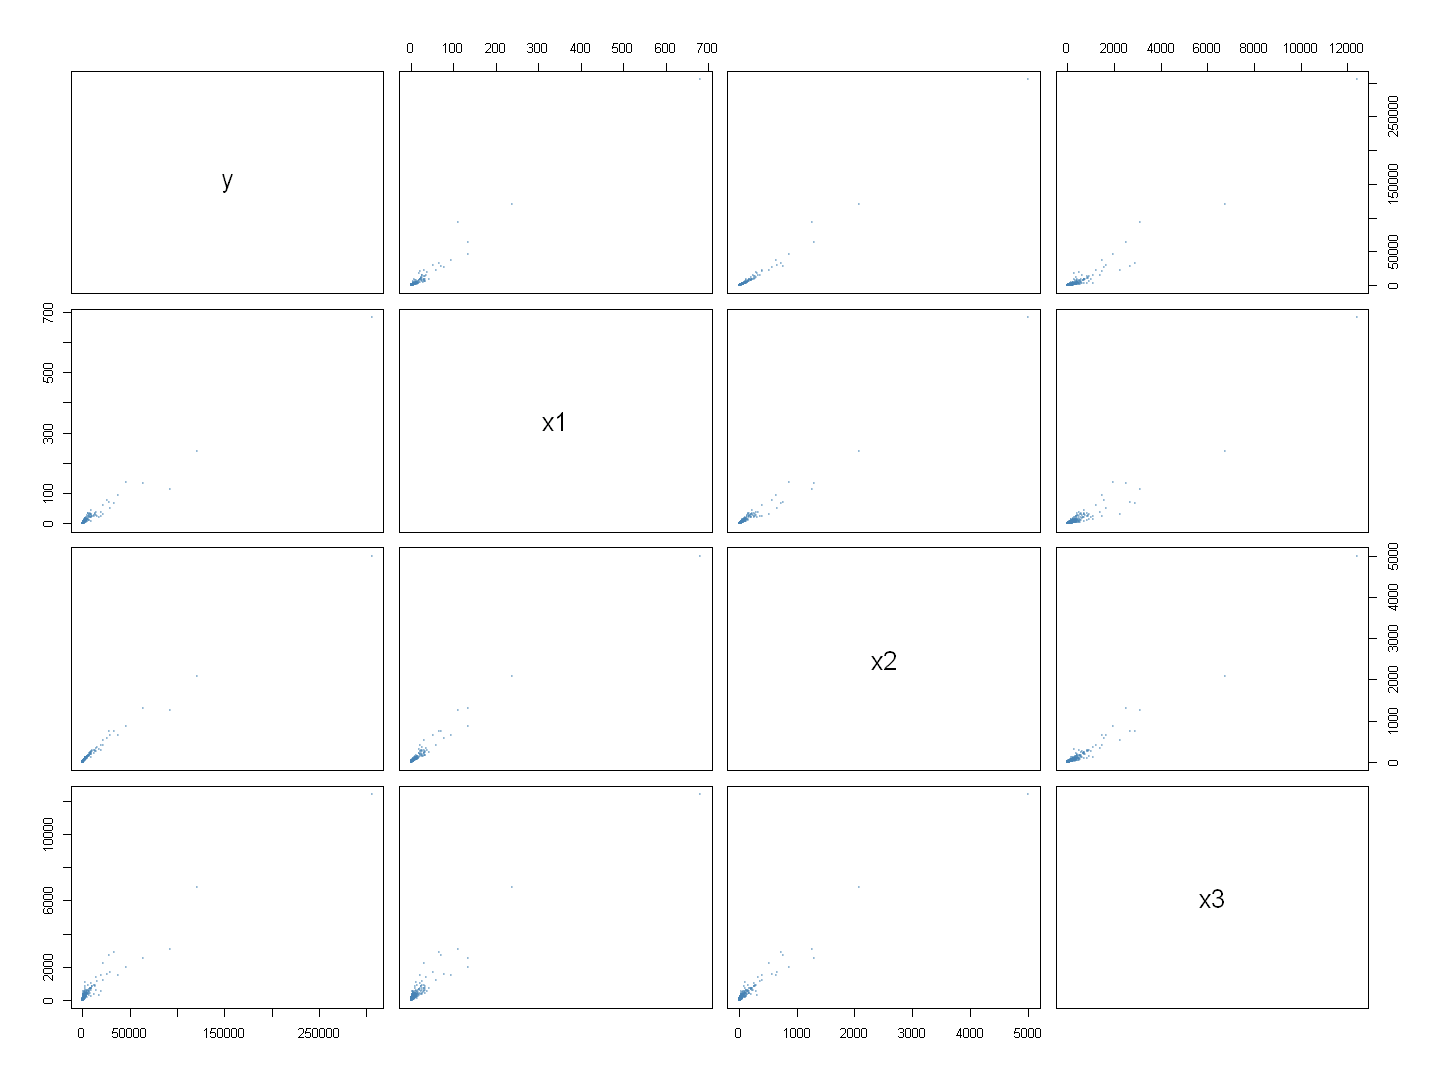

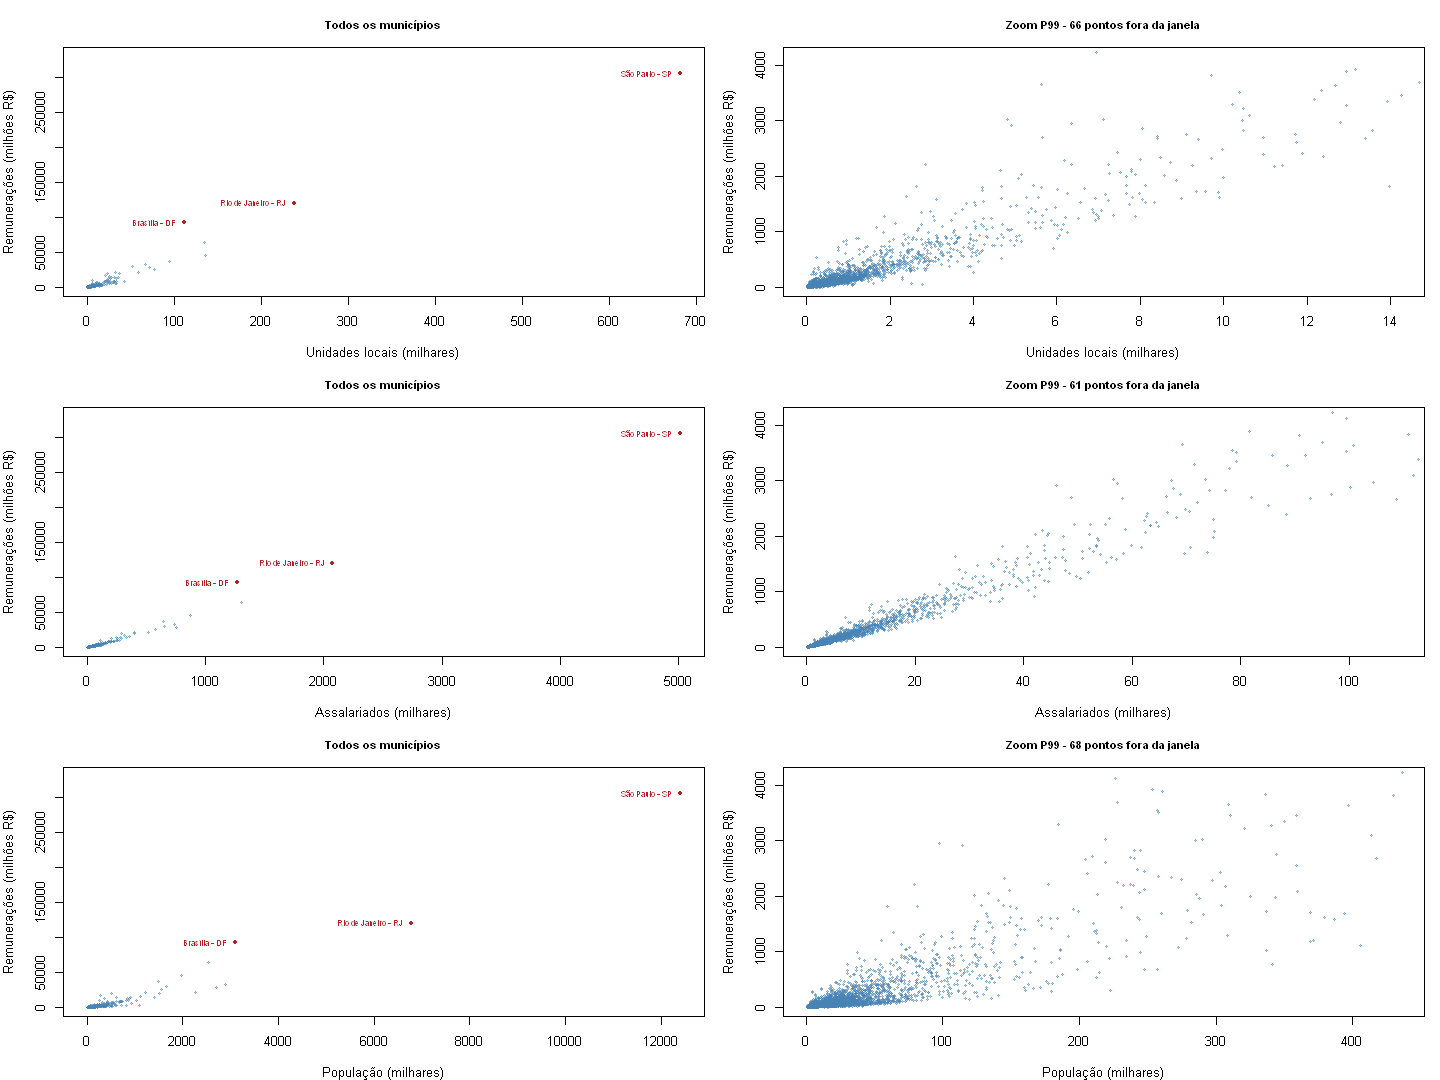

In [4]:
dados_originais <- data.frame(y,x1,x2,x3)
summary(dados_originais)
cor(dados_originais)
pairs(dados_originais,pch=19,cex=0.3,col=adjustcolor("steelblue",alpha.f=0.35))

par(mfrow=c(3,2),mar=c(4,4,3,1))
grafico_visual(x1,y,"Unidades locais (milhares)")
grafico_visual(x1,y,"Unidades locais (milhares)",zoom=TRUE)
grafico_visual(x2,y,"Assalariados (milhares)")
grafico_visual(x2,y,"Assalariados (milhares)",zoom=TRUE)
grafico_visual(x3,y,"População (milhares)")
grafico_visual(x3,y,"População (milhares)",zoom=TRUE)
par(mfrow=c(1,1))


## Transformações Box–Tidwell

Aplicamos `car::boxTidwell()` **separadamente** em cada relação Y × X, para procurar potências que aproximem as nuvens de pontos de retas. São transformações marginais, não potências estimadas simultaneamente para um modelo múltiplo. Todos os X são positivos. H0 do teste de escore: potência igual a 1. Os avisos de não convergência não devem ser ignorados.

As potências não serão arredondadas para outras transformações. Se uma estimativa fosse zero, usaríamos log(X); as estimativas obtidas aqui são diferentes de zero e usamos X elevado à potência estimada.

In [ ]:
bt1 <- car::boxTidwell(y~x1, max.iter=100, tol=0.0001)
bt2 <- car::boxTidwell(y~x2, max.iter=100, tol=0.0001)
bt3 <- car::boxTidwell(y~x3, max.iter=100, tol=0.0001)
bt1
bt2
bt3

lambda1 <- bt1$result[1,"MLE of lambda"]
lambda2 <- bt2$result[1,"MLE of lambda"]
lambda3 <- bt3$result[1,"MLE of lambda"]
potencias <- data.frame(variavel=c("x1","x2","x3"), lambda=c(lambda1,lambda2,lambda3), iteracoes=c(bt1$iterations,bt2$iterations,bt3$iterations))
potencias

stopifnot(all(is.finite(potencias$lambda)), all(potencias$iteracoes<=100))

 MLE of lambda Score Statistic (t) Pr(>|t|)    
         1.035               16.01   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

iterations =  3 

 MLE of lambda Score Statistic (t) Pr(>|t|)    
         1.095               75.19   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

iterations =  3 

 MLE of lambda Score Statistic (t) Pr(>|t|)    
         1.245               78.34   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

iterations =  3 

variavel,lambda,iteracoes
<chr>,<dbl>,<dbl>
x1,1.03469,3
x2,1.09461,3
x3,1.24527,3


## Acrescentar as variáveis transformadas e repetir os gráficos

variavel,antes,depois
<chr>,<dbl>,<dbl>
Unidades locais,0.984671,0.985296
Assalariados,0.992291,0.996094
População,0.957654,0.980440


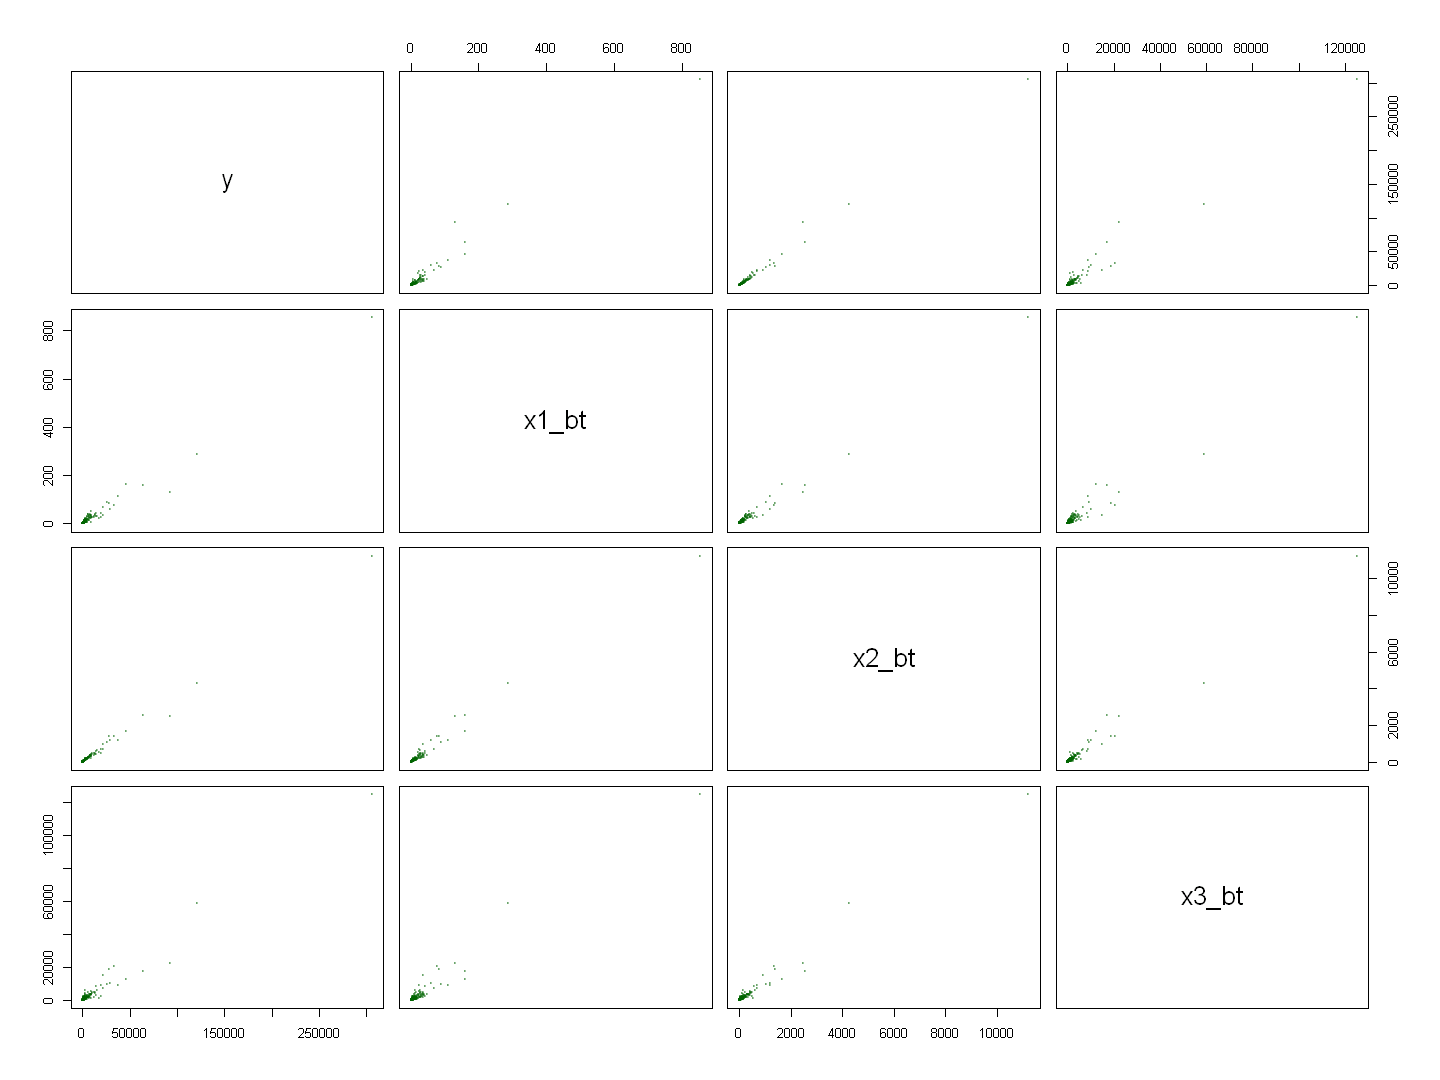

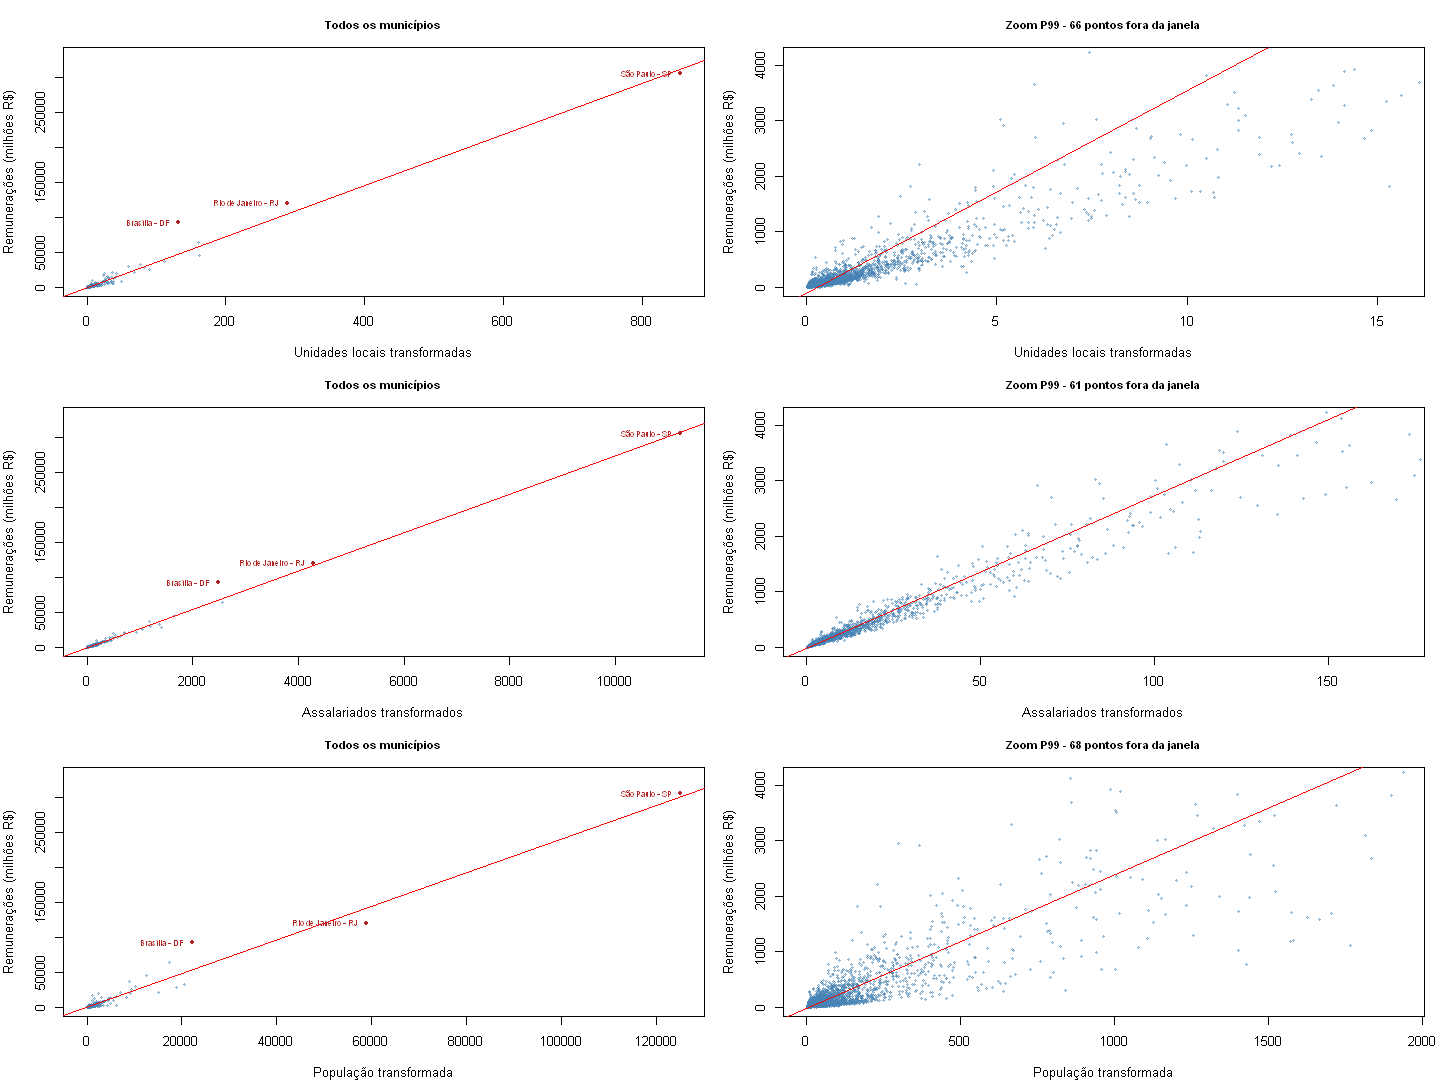

In [ ]:
x1_bt <- x1^lambda1
x2_bt <- x2^lambda2
x3_bt <- x3^lambda3

dados$x1_bt <- x1_bt
dados$x2_bt <- x2_bt
dados$x3_bt <- x3_bt
write.csv2(dados, "dados/transformados/base_com_transformacoes.csv", row.names=FALSE, fileEncoding="UTF-8")

comparacao <- data.frame(variavel=c("Unidades locais","Assalariados","População"), antes=c(cor(y,x1),cor(y,x2),cor(y,x3)), depois=c(cor(y,x1_bt),cor(y,x2_bt),cor(y,x3_bt)))
comparacao
pairs(data.frame(y,x1_bt,x2_bt,x3_bt),pch=19,cex=0.3, col=adjustcolor("darkgreen",alpha.f=0.35))

par(mfrow=c(3,2),mar=c(4,4,3,1))
grafico_visual(x1_bt,y,"Unidades locais transformadas",ajuste=lm(y~x1_bt))
grafico_visual(x1_bt,y,"Unidades locais transformadas",zoom=TRUE,ajuste=lm(y~x1_bt))
grafico_visual(x2_bt,y,"Assalariados transformados",ajuste=lm(y~x2_bt))
grafico_visual(x2_bt,y,"Assalariados transformados",zoom=TRUE,ajuste=lm(y~x2_bt))
grafico_visual(x3_bt,y,"População transformada",ajuste=lm(y~x3_bt))
grafico_visual(x3_bt,y,"População transformada",zoom=TRUE,ajuste=lm(y~x3_bt))
par(mfrow=c(1,1))


## Escolha da variável explicativa

As nuvens originais mostram associação positiva forte e concentração em municípios menores. Após Box–Tidwell, as relações ficam globalmente mais próximas de retas. As três estimativas convergiram em três iterações: potências de aproximadamente 1,0347 para unidades locais, 1,0946 para assalariados e 1,2453 para população. As correlações passaram, respectivamente, de: 0,9847 a 0,9853, 0,9923 a 0,9961 e 0,9577 a 0,9804.

Escolhemos **assalariados transformados**, pela relação econômica com a massa de remunerações e pela maior correlação linear com Y. Mantemos Y em milhões de reais e usamos as potências completas, sem arredondamento, nos cálculos. A partir daqui, `x` representa a explicativa escolhida. A escolha e as transformações usam a mesma amostra.

A análise é exploratória, sem validação externa. A adequação dos resíduos será avaliada separadamente.

In [7]:
x <- x2_bt  # (assalariados / 1000)^lambda2

# Análise descritiva


       x                  y           
 Min.   :4.30e-02   Min.   :8.80e-01  
 1st Qu.:4.95e-01   1st Qu.:1.37e+01  
 Median :1.16e+00   Median :3.11e+01  
 Mean   :1.36e+01   Mean   :3.58e+02  
 3rd Qu.:3.58e+00   3rd Qu.:9.24e+01  
 Max.   :1.12e+04   Max.   :3.06e+05  

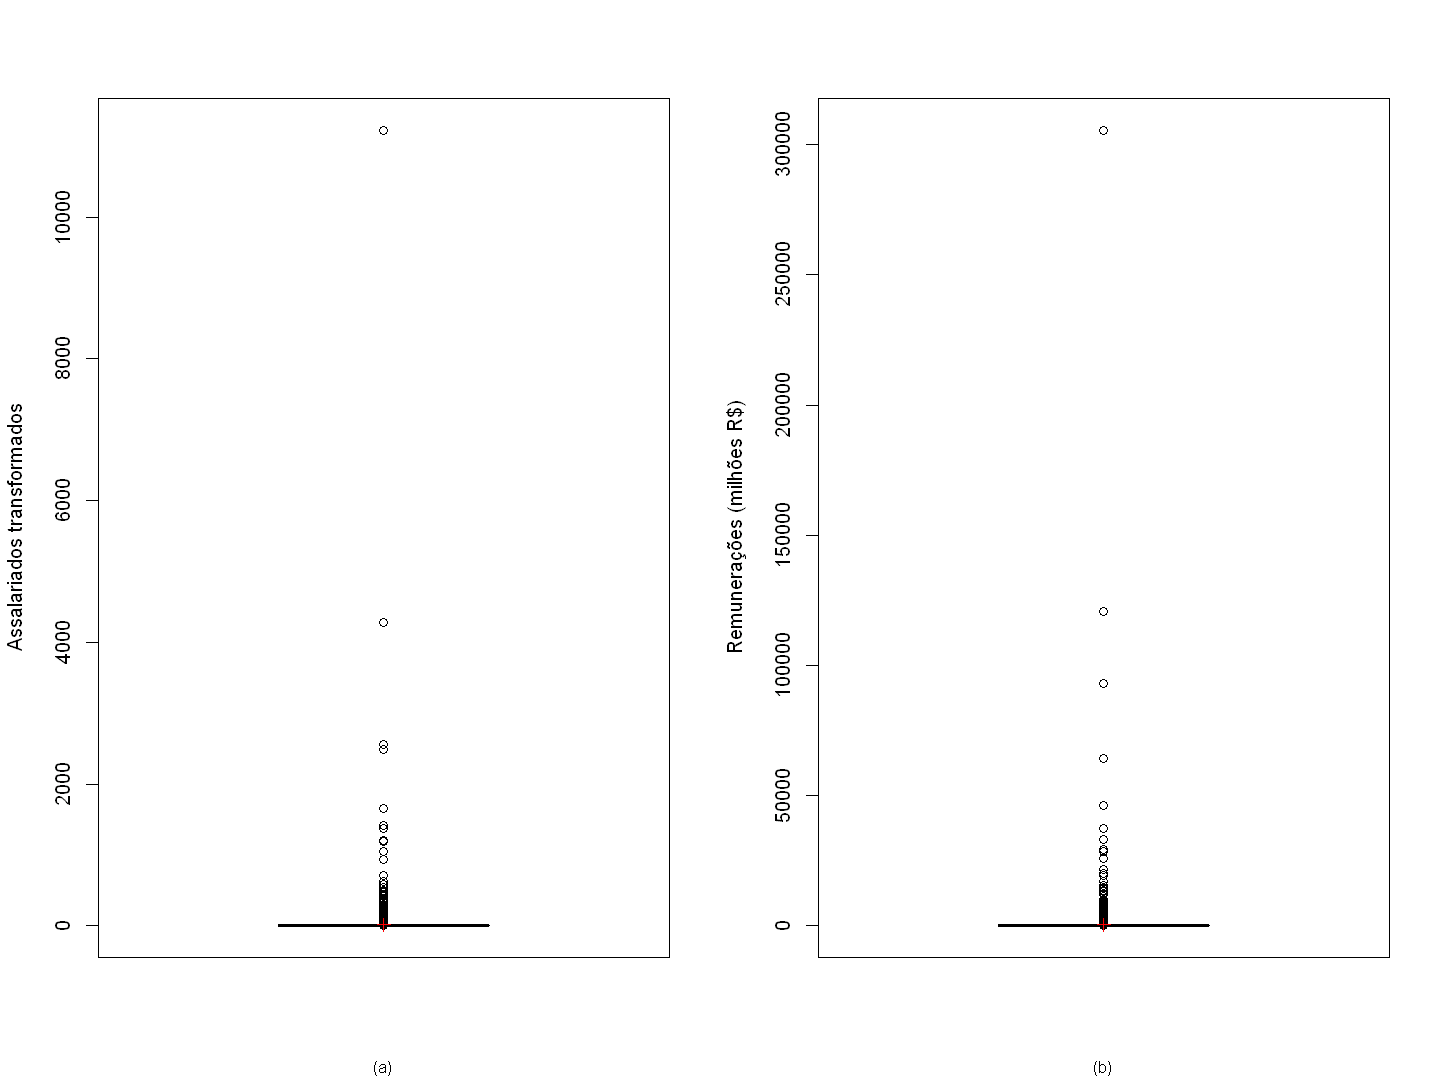

In [8]:
par(mfrow=c(1,2))
boxplot(x, ylab = "Assalariados transformados", col="orange")
points(mean(x),col="red",pch=3)
mtext("(a)", side=1, line=4, cex=0.8)

boxplot(y, ylab = "Remunerações (milhões R$)", col="orange")
points(mean(y),col="red",pch=3)
mtext("(b)", side=1, line=4, cex=0.8)


par(mfrow=c(1,1))
summary(data.frame(x,y))

# Coeficientes de correlação

## Coeficiente de Pearson


In [9]:
pearson <- cor(y,x)     # coeficiente de Pearson
pearson


[1] 0.996094

## Coeficiente de Spearman


In [10]:
spearman <- cor(y, x, method = "spearman")  # coeficiente de Spearman
spearman


[1] 0.986037

## Parte 2 — regressão linear simples

### Ajuste da reta

O modelo relaciona Y com a explicativa transformada x:

$$Y_i=\beta_0+\beta_1x_i+E_i,\qquad E(Y_i\mid x_i)=\beta_0+\beta_1x_i.$$

Os intervalos clássicos pressupõem erros com média zero, variância constante, independência e normalidade para a inferência exata.

In [11]:
modelo <- lm(y~x)   # ajuste da reta de regressão
summary(modelo) # estimativas e testes dos coeficientes



Call:
lm(formula = y ~ x)

Residuals:
   Min     1Q Median     3Q    Max 
-10202      7     15     18  24462 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) -15.3721     5.7983   -2.65    0.008 ** 
x            27.4504     0.0326  841.73   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 431 on 5568 degrees of freedom
Multiple R-squared:  0.992,	Adjusted R-squared:  0.992 
F-statistic: 7.09e+05 on 1 and 5568 DF,  p-value: <2e-16


### Equação ajustada, reta e intervalos

Com os valores arredondados apenas para apresentação,

$$X=\left(\frac{\text{assalariados}}{1000}\right)^{1{,}0946},\qquad
\widehat{Y}=-15{,}3721+27{,}4504X.$$

Y está em **milhões de reais de 2021**. A reta é linear em X transformado: uma unidade adicional nessa escala corresponde a cerca de 27,45 milhões de reais adicionais no valor estimado de Y, sem representar aumento por trabalhador. O intercepto corresponde a X igual a zero, fora da faixa observada.

O próximo gráfico reúne os **valores observados**, a **reta ajustada**, o **intervalo de confiança pontual de 95% para a média** e o **intervalo de predição pontual de 95% para uma nova observação municipal**. O intervalo de predição é mais largo por incluir a variabilidade de uma observação individual. São intervalos pontuais, não bandas simultâneas para toda a reta.

Os cenários calculados são quartis do emprego dentro da faixa observada, não previsões para anos futuros. Limites negativos ilustram a inadequação para pequenos totais positivos; a validade das faixas depende das suposições avaliadas adiante.

,x
,<dbl>
25%,0.494979
50%,1.163090
75%,3.582352


,fit,lwr,upr
25%,-1.78469,-847.712,844.142
50%,16.55519,-829.372,862.482
75%,82.96483,-762.962,928.892


,fit,lwr,upr
25%,-1.78469,-13.14920,9.57982
50%,16.55519,5.19375,27.91663
75%,82.96483,71.61317,94.31648


,fit,lwr,upr
25%,-1.78469,-711.673,708.103
50%,16.55519,-693.333,726.443
75%,82.96483,-626.923,792.853


,fit,lwr,upr
25%,-1.78469,-11.32160,7.75222
50%,16.55519,7.02085,26.08952
75%,82.96483,73.43870,92.49095


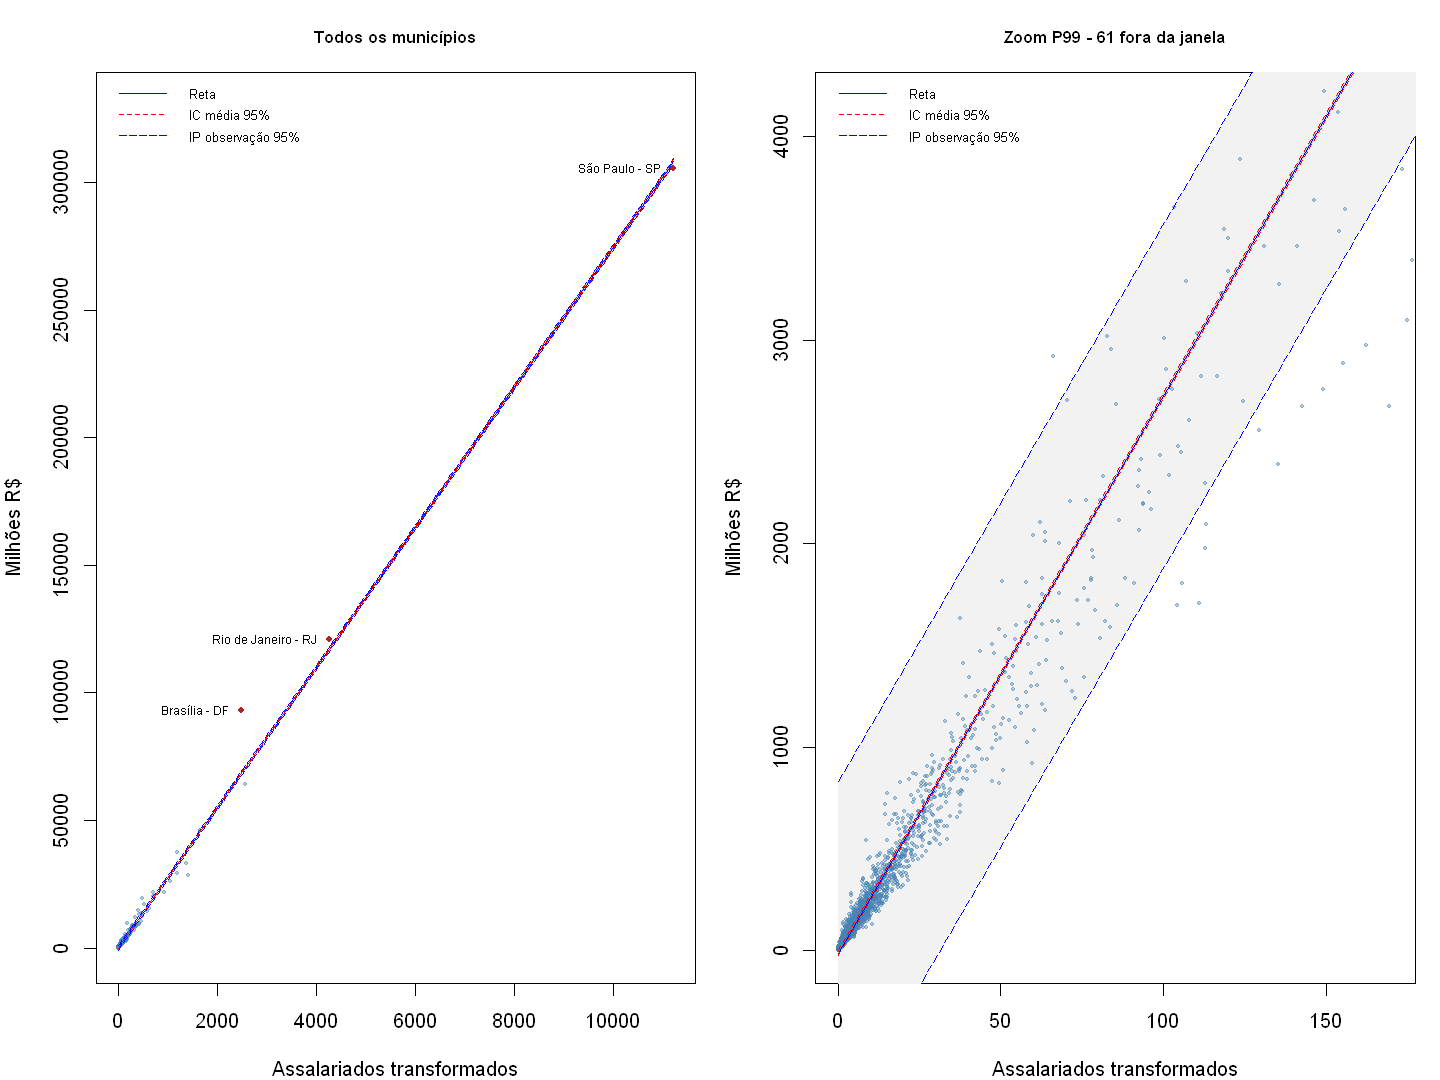

In [12]:
# Novas observações: quartis do emprego dentro da faixa observada
novos_assalariados <- quantile(dados$assalariados, c(0.25, 0.50, 0.75))
novos_x <- data.frame(x = (novos_assalariados/1000)^lambda2)
novos_x

int_conf_nova_obs <- predict(modelo, novos_x, interval="prediction")
int_conf_nova_obs
int_conf_media <- predict(modelo, novos_x, interval="confidence")
int_conf_media

# Exemplo considerando outro nível de confiança
predict(modelo, novos_x, level=0.90, interval="prediction")
predict(modelo, novos_x, level=0.90, interval="confidence")

# Diagrama com bandas para as médias e novas observações
novos_x <- seq(min(x), max(x), length.out=300)
int_conf_nova_obs <- predict(modelo, newdata=data.frame(x=novos_x), interval="prediction")
int_conf_media <- predict(modelo, newdata=data.frame(x=novos_x), interval="confidence")

par(mfrow=c(1,2),mar=c(4,4,3,1))
for (zoom in c(FALSE,TRUE)) {
  limite_x <- if (zoom) quantile(x,0.99) else max(x)
  limite_y <- if (zoom) quantile(y,0.99) else max(y)*1.08
  fora <- sum(x>limite_x | y>limite_y)
  titulo <- if (zoom) paste("Zoom P99 -",fora,"fora da janela") else "Todos os municípios"
  limite_inferior <- if (zoom) min(y) else min(y,int_conf_nova_obs)
  plot(y~x,type='n',xlim=c(min(x),limite_x),ylim=c(limite_inferior,limite_y),
       xlab="Assalariados transformados",ylab="Milhões R$",main=titulo,cex.main=0.85)
  polygon(c(rev(novos_x),novos_x),
          c(rev(int_conf_nova_obs[,3]),int_conf_nova_obs[,2]),col='grey95',border=NA)
  polygon(c(rev(novos_x),novos_x),
          c(rev(int_conf_media[,3]),int_conf_media[,2]),col='grey80',border=NA)
  points(x,y,pch=19,cex=0.45,col=adjustcolor("steelblue",alpha.f=0.4))
  
  lines(novos_x,int_conf_nova_obs[,1],col="blue")
  lines(novos_x,int_conf_nova_obs[,2],col="blue",lty=5)
  lines(novos_x,int_conf_nova_obs[,3],col="blue",lty=5)
  lines(novos_x,int_conf_media[,2],col="red",lty=2)
  lines(novos_x,int_conf_media[,3],col="red",lty=2)
  if (!zoom) {
    cidades <- order(y,decreasing=TRUE)[1:3]
    points(x[cidades],y[cidades],pch=19,cex=0.7,col="firebrick")
    text(x[cidades],y[cidades],labels=dados$municipio[cidades],pos=2,cex=0.6)
  }
  legend("topleft",c("Reta","IC média 95%","IP observação 95%"),
         col=c("blue","red","blue"),lty=c(1,2,5),bty="n",cex=0.65)
}
par(mfrow=c(1,1))

## Estimação de $\beta_0$ e $\beta_1$ na forma matricial


In [13]:
X<-model.matrix(modelo)
head(X)

# ou de forma manual
#n=10
#int<-matrix(1,n,1) # vetor de 1s
#X<-cbind(int,x);X  # matriz

Beta <- solve(t(X)%*%X)%*%t(X)%*%y # vetor com estimativas dos coeficientes
Beta

,(Intercept),x
1,1,2.554984
2,1,22.478269
3,1,0.460067
4,1,22.393764
5,1,2.427064
6,1,2.397534


(Intercept),-15.3721
x,27.4504


## Estimação da variância dos erros $\sigma^2$

Se as suposições do modelo são satisfeitas então o erro quadrático médio dos resíduos estima a variância dos erros
e portanto, a raiz quadrada do erro quadrático médio dos resíduos estima o erro padrão dos erros.


In [14]:
QMRes <- anova(modelo)[["Mean Sq"]][2]
QMRes

[1] 186167

## Estimação do erro padrão dos erros $\sigma$


In [15]:
raiz_QMRes <- sqrt(QMRes)
raiz_QMRes

[1] 431.471

## Tipos de resíduos

Os resíduos são utilizados na verificação das suposições do modelo de regressão e na identificação de observações atípicas. Existem diferentes tipos de resíduos, sendo alguns mais apropriados para a avaliação das suposições e outros para a identificação de observações atípicas.

Esses resíduos se distinguem pela forma como são calculados, especialmente pela maneira como consideram a variabilidade dos erros e a alavancagem das observações.

### Resíduos ordinários

Os resíduos ordinários são definidos como as diferenças entre os valores observados e os valores ajustados pelo modelo de regressão.

Sua expressão é:

$$
e_i = y_i - \hat{y}_i
$$

em que:

- $y_i$ é o valor observado da variável resposta;
- $\hat{y}_i$ é o valor ajustado pelo modelo.

No R, são calculados pela função `resid(modelo)`.

In [16]:
residuos<-resid(modelo)
head(residuos)

1          2          3          4          5          6 
  13.86579 -112.90074   16.91506 -126.09405   14.25826    5.67986

### Resíduos padronizados

Os resíduos padronizados são obtidos dividindo cada resíduo ordinário pela estimativa do desvio-padrão dos erros.

Sua expressão é:

$$
z_i = \frac{e_i}{\hat{\sigma}}
    = \frac{y_i-\hat{y}_i}{\sqrt{QM_{\text{Erro}}}}
$$

em que:

- $e_i=y_i-\hat{y}_i$ é o resíduo ordinário;
- $\hat{\sigma}^2=QM_{\text{Erro}}$ é a estimativa da variância dos erros;
- $\hat{\sigma}=\sqrt{QM_{\text{Erro}}}$ é a estimativa do desvio-padrão dos erros.

No R, os resíduos padronizados podem ser calculados por:

`resid(modelo) / sigma(modelo)`

Ver e-book MONTGOMERY, D.C.; RUNGER, G. Estatística Aplicada e Probabilidade para Engenheiros.


In [17]:
estimativa_ep_erro <- raiz_QMRes
res_padronizado <- residuos / estimativa_ep_erro
head(res_padronizado)

1          2          3          4          5          6 
 0.0321361 -0.2616650  0.0392033 -0.2922425  0.0330457  0.0131640

### Resíduo studentizado internamente

O resíduo studentizado internamente é calculado pela função `rstandard(modelo)` no R.

Sua expressão é:

$$
r_i = \frac{e_i}{\hat{\sigma}\sqrt{1-h_{ii}}}
$$

em que:

- $e_i = y_i - \hat{y}_i$ é o resíduo ordinário;
- $\hat{\sigma} = \sqrt{QM_{\text{Resíduo}}}$ é a estimativa do desvio-padrão dos erros;
- $h_{ii}$ é o elemento da diagonal principal da matriz de projeção:

$$
H = X(X'X)^{-1}X'
$$

O resíduo studentizado internamente também é denominado **resíduo padronizado internamente**.

Ver Anderson,D.R.;Sweeney,D.J.;Williams,T.A.;Camm,J.D.;Cochran,J.J.
Estatística aplicada a administração e economia.



In [18]:
res_pad<-rstandard(modelo)
head(res_pad)

1          2          3          4          5          6 
 0.0321390 -0.2616886  0.0392068 -0.2922688  0.0330487  0.0131651

### Resíduos studentizados externamente (utilizado na análise de influencia)

Os resíduos studentizados externamente são obtidos dividindo cada resíduo ordinário por uma estimativa de seu desvio-padrão, calculada sem considerar a observação correspondente. Esses resíduos são especialmente úteis na identificação de observações atípicas.

Sua expressão é:

$$
t_i = \frac{e_i}{\hat{\sigma}_{(i)}\sqrt{1-h_{ii}}}
$$

em que:

- $e_i=y_i-\hat{y}_i$ é o resíduo ordinário;
- $\hat{\sigma}_{(i)}$ é a estimativa do desvio-padrão dos erros, obtida sem a observação $i$;
- $h_{ii}$ é o elemento da diagonal principal da matriz de projeção $H=X(X'X)^{-1}X'$.

No R, são calculados pela função `rstudent(modelo)`.

In [19]:
r_studentizado <- rstudent(modelo)
head(r_studentizado)

1          2          3          4          5          6 
 0.0321361 -0.2616667  0.0392033 -0.2922448  0.0330458  0.0131640

# Verificação das suposições do modelo de regressão

## Para verificar as Suposições do Modelo

Para verificar se as suposições assumidas $E_{i}$~$N(0,\sigma^{2})$ e $cov(E_{i},E_{j})=0$ para $i\ne j$ são satisfeitas utilizamos os resíduos (valor observado - valor ajustado) já que os erros aleatórios no modelo são desconhecidos.

Os resíduos mais apropriados para a verificação das suposições do modelo são os resíduos studentizados internamente.

## Análise gráfica dos resíduos

O painel reúne boxplot dos resíduos externos, Q–Q dos resíduos internos, resíduos versus valores ajustados e escala e localização. Procuramos desvios nas caudas, padrões sistemáticos e mudanças de dispersão.

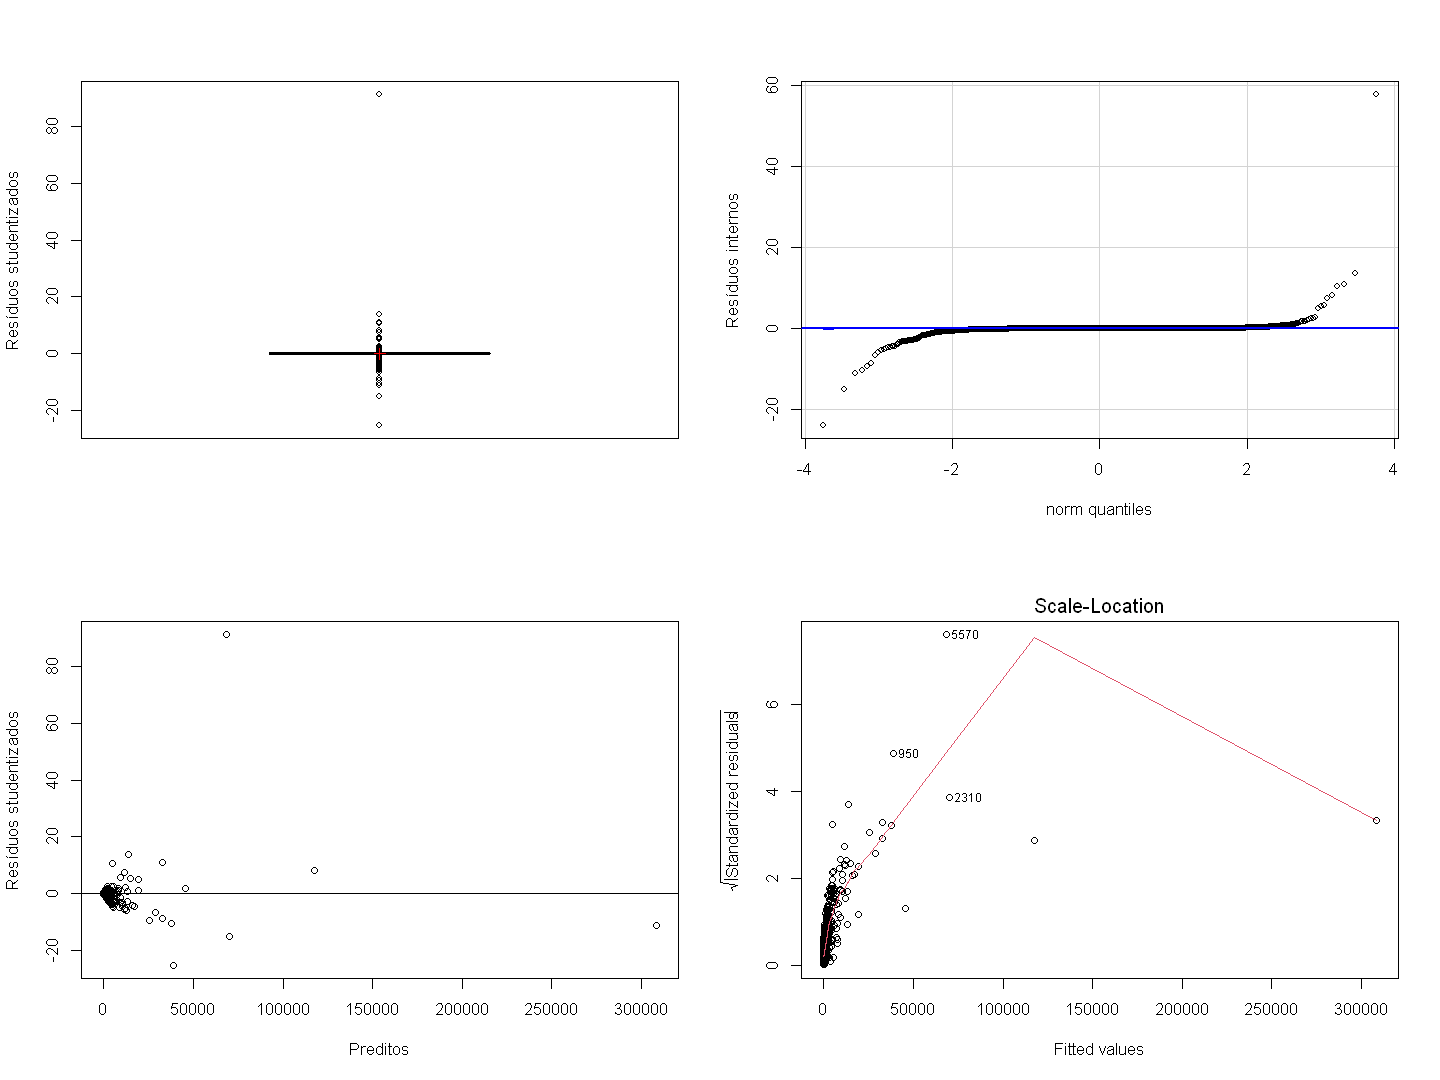

In [20]:
preditos <- predict(modelo)

par(mfrow=c(2,2))
boxplot(r_studentizado, ylab="Resíduos studentizados")
points(mean(r_studentizado),col="red",pch=3)

car::qqPlot(rstandard(modelo), envelope=0.95, ylab="Resíduos internos", id=FALSE)

plot(preditos, r_studentizado, xlab="Preditos", ylab="Resíduos studentizados")
abline(h=0)

plot(modelo, which=3)  # Escala e localização: avaliar variância constante

par(mfrow=c(1,1))

### Interpretação dos diagnósticos

O Q–Q apresenta desvios fortes nas caudas, incompatíveis com normalidade. Nos resíduos versus ajustados e no gráfico de escala e localização, a dispersão varia com o porte dos valores previstos, indicando heterocedasticidade. Observações extremas e padrões dos resíduos também exigem cautela quanto à forma linear. Os testes seguintes complementam essa leitura gráfica.

## Testes de normalidade

São utilizadas as 5.570 observações.
Shapiro–Wilk e Shapiro–Francia não são aplicados porque o tamanho excede 5.000, então usamos Anderson–Darling, Lilliefors e o gráfico Q–Q.

H0 é normalidade dos erros, adotamos 5%.


In [21]:
# Testes de normalidade
t_norm_ad <- nortest::ad.test(rstandard(modelo))
t_norm_lillie <- nortest::lillie.test(rstandard(modelo))
alpha_norm <- 0.05

resultados_norm <- data.frame(
  Teste = c("Anderson–Darling", "Lilliefors"),
  Estatistica = c(unname(t_norm_ad$statistic), unname(t_norm_lillie$statistic)),
  p_valor = c(t_norm_ad$p.value, t_norm_lillie$p.value)
)
resultados_norm$Decisao <- ifelse(resultados_norm$p_valor <= alpha_norm, "Rejeitar H0", "Não rejeitar H0")
resultados_norm

Teste,Estatistica,p_valor,Decisao
<chr>,<dbl>,<dbl>,<chr>
Anderson–Darling,1730.516196,3.7e-24,Rejeitar H0
Lilliefors,0.415136,0.0e+00,Rejeitar H0


## Testes para checar homogeneidade de variâncias


In [22]:
# testes de homogeneidade de variâncias
bptest(modelo) # Breusch-Pagan
ncvTest(modelo)



	studentized Breusch-Pagan test

data:  modelo
BP = 340.5, df = 1, p-value <2e-16


Non-constant Variance Score Test 
Variance formula: ~ fitted.values 
Chisquare = 329995, Df = 1, p = < 2.2e-16

## Gráfico para verificar a necessidade de transformação em $y$

O perfil de Box–Cox ajuda a investigar outra escala para Y. Se o intervalo de confiança para a potência não incluir 1, há evidência para investigar uma transformação da resposta. Ele não comprova, isoladamente, que os demais pressupostos foram satisfeitos. Box–Cox atua em Y, enquanto Box–Tidwell, aplicado antes, atua nas explicativas.

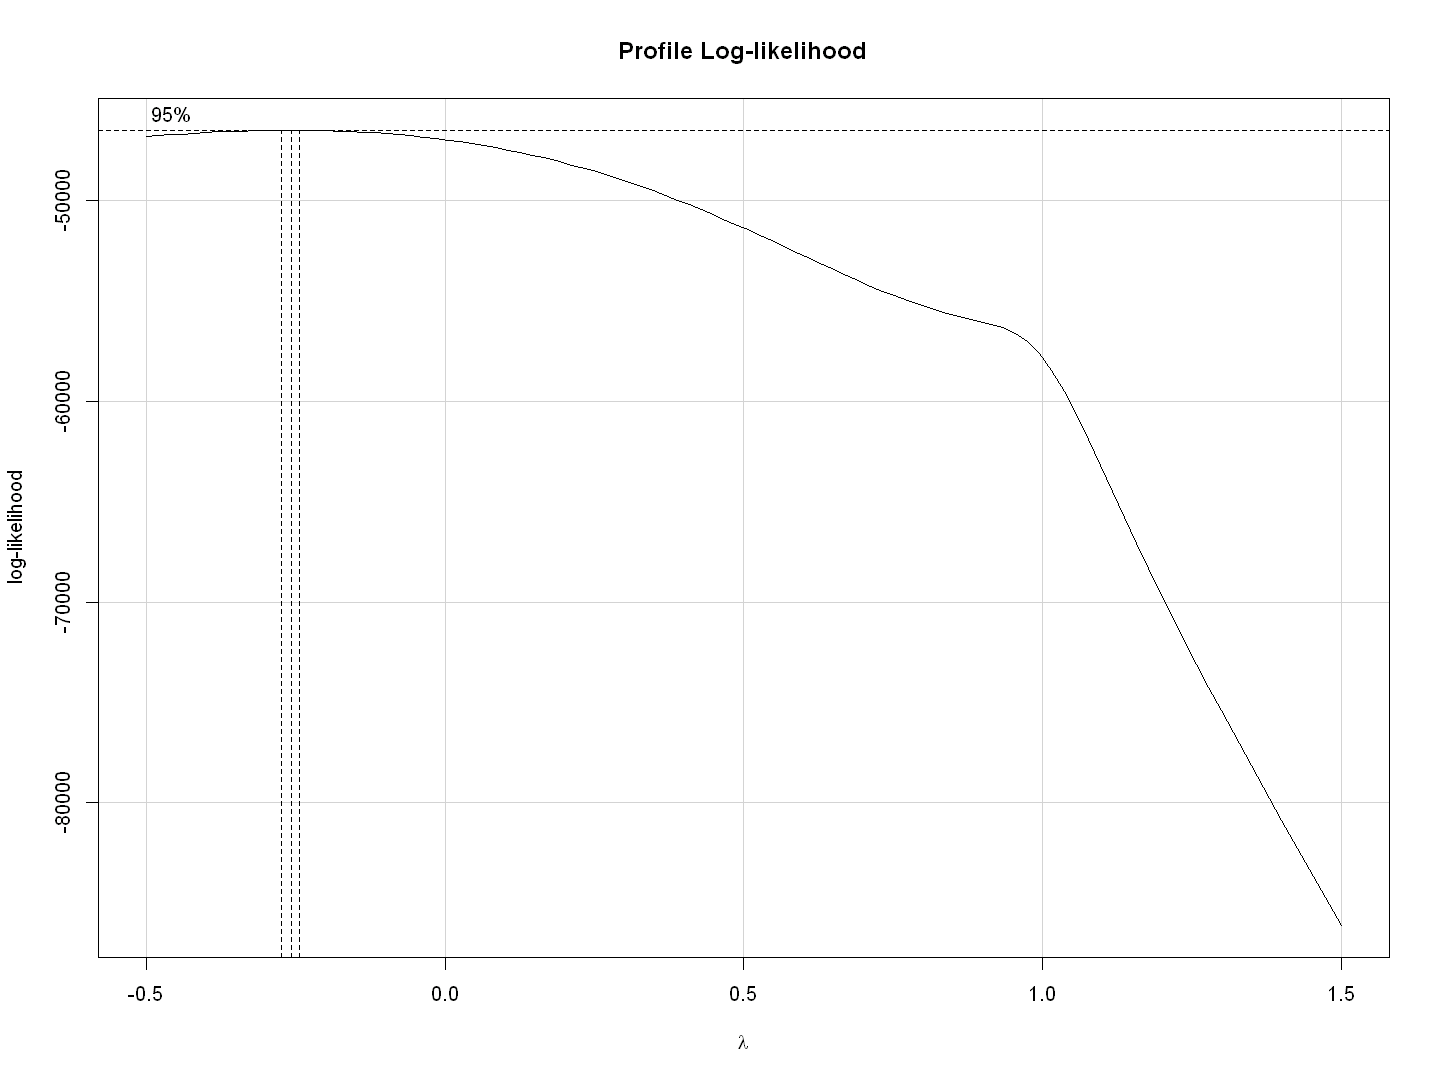

In [23]:
boxCox(modelo, lambda=seq(-0.5, 1.5, 0.01))

Neste caso, o perfil indica potência próxima de −0,26, e 1 fica fora do intervalo aproximado.
Há motivo para investigar transformação de Y em uma próxima análise.
Aqui mantemos Y em milhões de reais para apresentar a regressão solicitada, reconhecendo que a normalidade e a variância constante não são atendidas. Transformar X não resolveu todos os problemas do modelo.

## Teste para checar autocorrelação entre os resíduos


Os dados não têm ordem temporal, aplicar Durbin–Watson aos códigos dos municípios não comprovaria independência. Não executamos esse teste e registramos a possibilidade de dependência espacial como limitação.


## Teste para checar outliers


In [24]:
outlierTest(modelo)


     rstudent unadjusted p-value Bonferroni p
5570  91.0772         0.0000e+00   0.0000e+00
950  -25.0862        1.1430e-131  6.3667e-128
2310 -15.1560         7.0848e-51   3.9463e-47
4399  13.9307         2.1916e-43   1.2207e-39
3830 -11.1214         1.9645e-28   1.0943e-24
4932  10.9514         1.2494e-27   6.9593e-24
3212  10.5486         9.0164e-26   5.0221e-22
2163 -10.3762         5.3727e-25   2.9926e-21
112   -9.3251         1.5637e-20   8.7098e-17
1597  -8.5937         1.0806e-17   6.0191e-14

## Tabela de Análise de Variância


In [25]:
anova(modelo)

#require(EnvStats)
#anovaPE(modelo) # nesse caso a anova inclui o teste de falta de ajuste (APENAS NO CASO DE DADOS COM MEDIDAS REPETIDAS PARA CADA x)

SQR <- sum((preditos-mean(y))^2); SQR  # soma de quadrados regressão
SQRes <- sum((y-preditos)^2); SQRes    # soma de quadrados dos erros
SQT <- sum((y-mean(y))^2); SQT         # soma de quadrados total

#soma de quadrados do erro puro (SQEPuro) = desvios ao quadrado dos valores de y com relação aos valores médios de y para cada x
#soma de quadrados de falta de ajuste = SqRes - SQEPuro


,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
x,1,1.31900e+11,1.31900e+11,708502,0
Residuals,5568,1.03658e+09,1.86167e+05,NA,NA


[1] 1.319e+11

[1] 1036576886

[1] 1.32936e+11

## Intervalos de confiança para $\beta_0$ e $\beta_1$


In [26]:
#### ou (obtencao passo a passo)
# intervalos de confianca para beta0, beta1

coef=summary(modelo)$coefficients[1,1] ; coef
err=summary(modelo)$coefficients[1,2] ; err
coef + c(-1,1)*err*qt(0.975, (length(y)-2))  # intervalos de confiança para beta0

coef=summary(modelo)$coefficients[2,1] ; coef
err=summary(modelo)$coefficients[2,2] ; err
coef + c(-1,1)*err*qt(0.975, (length(y)-2))  # intervalos de confiança para beta1

confint(modelo)

[1] -15.3721

[1] 5.79828

[1] -26.73894  -4.00517

[1] 27.4504

[1] 0.032612

[1] 27.3864 27.5143

,2.5 %,97.5 %
(Intercept),-26.7389,-4.00517
x,27.3864,27.51430


## Análise de influência

Uma observação influente é aquela cuja omissão do conjunto de dados resulta em grandes mudanças em certos aspectos do modelo.


[1] 5570

[1] 2

[1] 0.000718133

,(Intercept),x
1,0.000,0
2,-0.003,0
3,0.001,0
4,-0.004,0
5,0.000,0
6,0.000,0


[1] 0.0568574

1      2      3      4      5      6 
 0.000 -0.004  0.001 -0.004  0.000  0.000

[1] 0.693233

1 2 3 4 5 6 
0 0 0 0 0 0

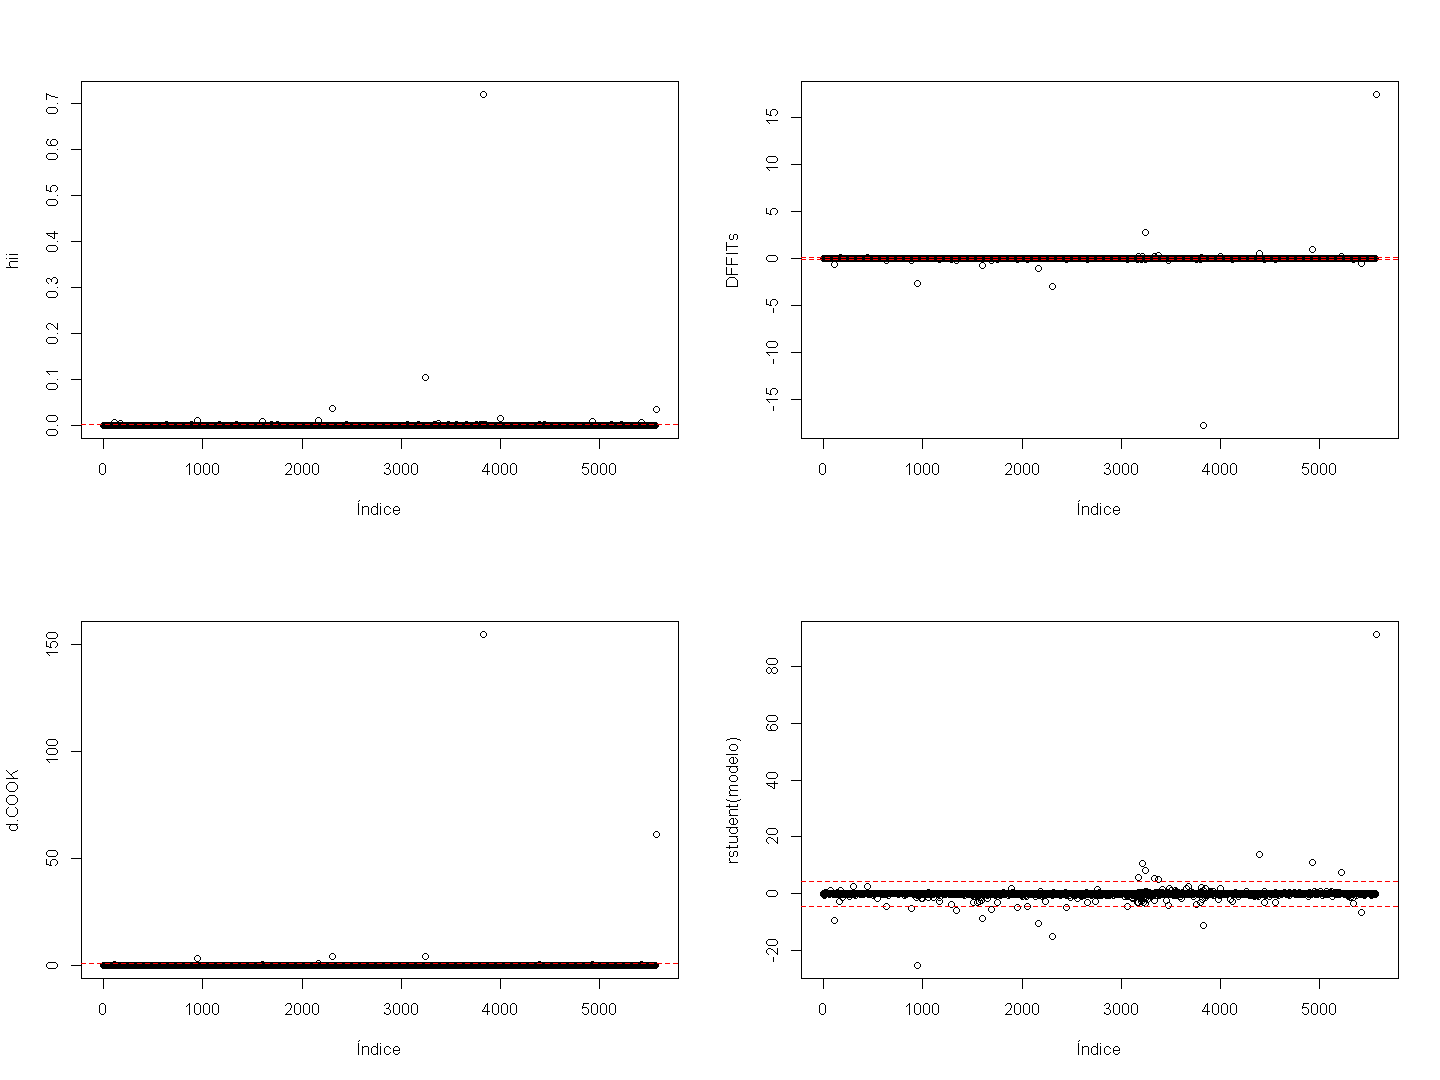

In [27]:
# Análise de pontos influentes
inf <- influence.measures(modelo)

# Elementos hii da diagonal da matriz de projeção H
hii <- hatvalues(modelo)
n <- length(y); n
p <- ncol(model.matrix(modelo)); p
pad_lev <- 2*p/n; pad_lev

# DFBETAS: mudanças nos coeficientes
DBETAs <- dfbetas(modelo)
head(round(DBETAs,3))

# DFFITS: mudanças nos valores ajustados
pad_Fit <- 3*sqrt(p/(n-p)); pad_Fit
DFFITs <- dffits(modelo)
head(round(DFFITs,3))

# Distância de Cook
pad_Cook <- qf(0.5,p,n-p,lower.tail=FALSE); pad_Cook
d.COOK <- cooks.distance(modelo)
head(round(d.COOK,3))

par(mfrow=c(2,2))
plot(hii,xlab="Índice"); abline(h=pad_lev,col="red",lty=2)
plot(DFFITs,xlab="Índice"); abline(h=c(-pad_Fit,pad_Fit),col="red",lty=2)
plot(d.COOK,xlab="Índice"); abline(h=pad_Cook,col="red",lty=2)
plot(rstudent(modelo),xlab="Índice")
abline(h=c(-1,1)*qt(1-0.05/(2*n),n-p-1),col="red",lty=2)
par(mfrow=c(1,1))

### Municípios com maior influência

Alavancagem indica um X extremo; resíduo elevado indica distância vertical à reta; influência indica alteração potencial no ajuste. A tabela ordenada por Cook identifica as cidades que mais afetam o modelo. Uma cidade grande não é automaticamente um erro de registro: nenhuma é excluída.

Referência: apostila *Modelos de Regressão*, Demétrio e Zocchi.

In [28]:
# hatvalues evita montar a matriz H de 5570 por 5570 elementos
head(hatvalues(modelo))

influencia <- data.frame(municipio=dados$municipio,
                         residuo_externo=rstudent(modelo),
                         leverage=hii, DFFITS=DFFITs, Cook=d.COOK)
head(influencia[order(-influencia$Cook),],10)
write.csv2(influencia, "dados/diagnosticos/influencia.csv",row.names=FALSE,
           fileEncoding="UTF-8")

1           2           3           4           5           6 
0.000180231 0.000179983 0.000180521 0.000179974 0.000180247 0.000180251

,municipio,residuo_externo,leverage,DFFITS,Cook
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
3830,São Paulo - SP,-11.12137,0.71826345,-17.757371,154.263090
5570,Brasília - DF,91.07724,0.03531369,17.425624,60.984297
2310,Belo Horizonte - MG,-15.15598,0.03733896,-2.984890,4.279025
3243,Rio de Janeiro - RJ,8.21261,0.10410648,2.799575,3.872594
950,Fortaleza - CE,-25.08616,0.01136514,-2.689699,3.250446
2163,Salvador - BA,-10.37616,0.01075455,-1.081885,0.574237
4932,Porto Alegre - RS,10.95145,0.00806930,0.987754,0.477627
1597,Recife - PE,-8.59370,0.00822621,-0.782661,0.302323
112,Manaus - AM,-9.32510,0.00506064,-0.665055,0.217787


## Extensão ao objetivo geral: regressão linear múltipla

Regressão simples para a primeira etapa.
Para também ilustrar o objetivo geral do trabalho, ajustamos abaixo um modelo com as três candidatas transformadas. As potências continuam sendo as marginais da exploração anterior.

In [29]:
modelo_multiplo <- lm(y~x1_bt+x2_bt+x3_bt)
summary(modelo_multiplo)
confint(modelo_multiplo)
vif(modelo_multiplo)


Call:
lm(formula = y ~ x1_bt + x2_bt + x3_bt)

Residuals:
   Min     1Q Median     3Q    Max 
-11740      1      6     14  19759 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  -0.2833     5.5632   -0.05     0.96    
x1_bt       -53.6990     3.1926  -16.82   <2e-16 ***
x2_bt        35.2716     0.3250  108.54   <2e-16 ***
x3_bt        -0.3480     0.0176  -19.78   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 410 on 5566 degrees of freedom
Multiple R-squared:  0.993,	Adjusted R-squared:  0.993 
F-statistic: 2.62e+05 on 3 and 5566 DF,  p-value: <2e-16


,2.5 %,97.5 %
(Intercept),-11.189412,10.622841
x1_bt,-59.957737,-47.440344
x2_bt,34.634544,35.908634
x3_bt,-0.382489,-0.313509


x1_bt    x2_bt    x3_bt 
 58.6928 109.9966  40.7506

## Resultados e conclusão

A análise confirma associação positiva forte entre as três medidas de porte municipal e a massa de remunerações. As transformações melhoraram as correlações lineares, e o emprego assalariado transformado foi escolhido para o modelo simples. Para essa explicativa, Pearson foi **0,9961** e Spearman **0,9860**. O modelo teve **R² de 0,9922**, R² ajustado de **0,9922** e desvio-padrão residual de aproximadamente **431,47 milhões de reais**. Os testes global F e da inclinação apresentaram p < 0,001 sob as hipóteses clássicas.

Os diagnósticos gráficos, confirmados pelos testes de normalidade e de variância, mostram que o modelo clássico não atende a todas as suposições. Portanto, o ajuste forte na amostra não basta para recomendar previsão nem para afirmar cobertura nominal de 95% dos intervalos apresentados. A independência espacial permanece não verificada. São Paulo e Brasília destacam-se na influência sobre o ajuste.

A extensão múltipla tem R² de aproximadamente **0,9930**, mas VIFs entre cerca de 41 e 110: as explicativas medem porte municipal e suas contribuições não devem ser interpretadas isoladamente como efeitos econômicos. O ganho de R² não demonstra superioridade por si só.

Respondemos às perguntas iniciais com uma associação descritiva forte e uma reta estimada, acompanhadas de limitações claras para inferência e previsão. Os dados são agregados, observacionais e restritos à atividade formal de 2021, sem conclusões causais ou individuais. Investigar outra escala para Y e uma estrutura de erros mais adequada fica para etapas futuras.

## Arquivos da entrega no GitHub

- [Base original](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/originais/base_original.csv): variáveis antes das transformações.
- [Base com transformações](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/transformados/base_com_transformacoes.csv): variáveis originais e transformadas na mesma planilha.
- [Diagnóstico de influência](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/diagnosticos/influencia.csv): medidas de influência por município.
- [Gráficos exportados e validação](https://github.com/embertoni/TrabalhoFinal-IAR/tree/main/parte1/resultados).

As tabelas e os gráficos também aparecem nas saídas do notebook. As fontes do IBGE estão identificadas na introdução.